<a href="https://colab.research.google.com/github/DishitaRathore/credit-card-fraud-xgboost/blob/main/notebooks/credit_card.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install xgboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
)

print("Setup complete")
print("XGBoost version:", xgb.__version__)
print("Pandas version:", pd.__version__)


Setup complete
XGBoost version: 3.4.1
Pandas version: 2.2.3


In [12]:
df = pd.read_csv("/content/sample_data/creditcard.csv")

# Basic checks
if "Class" not in df.columns:
    raise ValueError(f"Expected a 'Class' column. Found: {list(df.columns)}")

if df["Class"].isna().any():
    raise ValueError("The dataset contains rows with missing Class labels.")

if set(df["Class"].unique()) != {0, 1}:
    raise ValueError("Expected Class values 0 (legitimate) and 1 (fraud).")

print("Dataset shape:", df.shape)
print("\nClass counts:")
print(df["Class"].value_counts().sort_index())
print(f"\nFraud rate: {df['Class'].mean():.4%}")
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

display(df.head())

Dataset shape: (284807, 31)
Dataset shape: (284807, 31)

Class counts:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud rate: 0.1727%
Missing values: 0
Duplicate rows: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,transaction_type,count,percentage
0,Legitimate (0),284315,99.827251
1,Fraud (1),492,0.172749


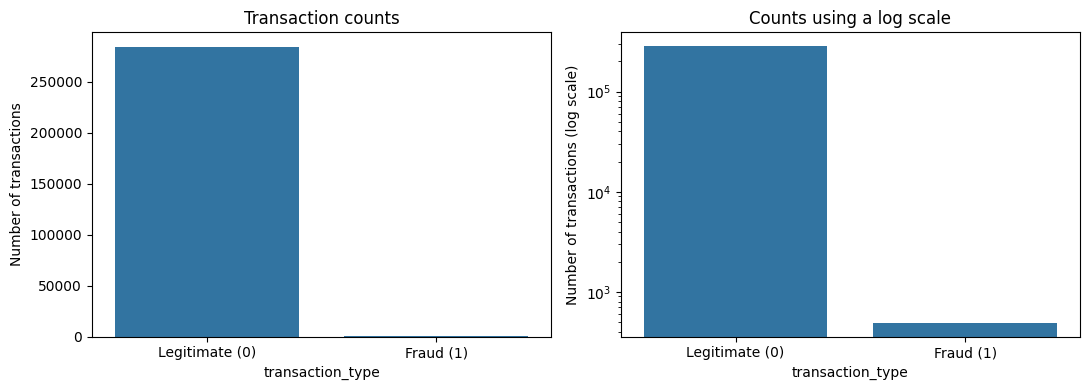

Transaction amount summary:


,count,median,mean,max
Class,,,,
Legitimate,284315,22.00,88.291022,25691.16
Fraud,492,9.25,122.211321,2125.87


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

if df["Class"].isna().any():
    raise ValueError("Class still contains missing values. Check Step 2.")

class_counts = df["Class"].value_counts().sort_index()

summary = pd.DataFrame({
    "transaction_type": ["Legitimate (0)", "Fraud (1)"],
    "count": [class_counts.get(0, 0), class_counts.get(1, 0)],
})
summary["percentage"] = summary["count"] / len(df) * 100

display(summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(data=summary, x="transaction_type", y="count", ax=axes[0])
axes[0].set_title("Transaction counts")
axes[0].set_ylabel("Number of transactions")

sns.barplot(data=summary, x="transaction_type", y="count", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Counts using a log scale")
axes[1].set_ylabel("Number of transactions (log scale)")

plt.tight_layout()
plt.show()

if "Amount" in df.columns:
    print("Transaction amount summary:")
    display(
        df.groupby("Class")["Amount"]
          .agg(["count", "median", "mean", "max"])
          .rename(index={0: "Legitimate", 1: "Fraud"})
    )

In [15]:
X = df.drop(columns=["Class"]).copy()
y = df["Class"].astype("int8").copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [16]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

for name, labels in [
    ("Train", y_train),
    ("Validation", y_valid),
    ("Test", y_test),
]:
    print(
        f"{name:10s} | rows: {len(labels):,} "
        f"| frauds: {int(labels.sum()):,} "
        f"| fraud rate: {labels.mean():.4%}"
    )

Train      | rows: 199,364 | frauds: 344 | fraud rate: 0.1725%
Validation | rows: 42,721 | frauds: 74 | fraud rate: 0.1732%
Test       | rows: 42,722 | frauds: 74 | fraud rate: 0.1732%


In [17]:
legitimate_count = (y_train == 0).sum()
fraud_count = (y_train == 1).sum()

if fraud_count == 0:
    raise ValueError("No fraud cases in the training split.")

scale_pos_weight = legitimate_count / fraud_count

print("Legitimate transactions in training set:", legitimate_count)
print("Fraud transactions in training set:", fraud_count)
print("scale_pos_weight:", round(scale_pos_weight, 2))

Legitimate transactions in training set: 199020
Fraud transactions in training set: 344
scale_pos_weight: 578.55


In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Baseline 1: always predicts the majority class.
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

# Baseline 2: class-weighted logistic regression.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    )
)
logistic_model.fit(X_train, y_train)

print("Dummy and logistic regression baselines are trained.")

Dummy and logistic regression baselines are trained.


In [19]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=2,
    reg_lambda=2.0,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=False
)

print("XGBoost model trained.")

XGBoost model trained.


In [20]:
def evaluate_model(name, model, X_eval, y_eval):
    probabilities = model.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= 0.5).astype("int8")

    return {
        "Model": name,
        "Accuracy": (predictions == y_eval.to_numpy()).mean(),
        "Precision": precision_score(y_eval, predictions, zero_division=0),
        "Recall": recall_score(y_eval, predictions, zero_division=0),
        "F1": f1_score(y_eval, predictions, zero_division=0),
        "Average Precision": average_precision_score(y_eval, probabilities),
        "ROC-AUC": roc_auc_score(y_eval, probabilities),
    }

results = pd.DataFrame([
    evaluate_model("Dummy", dummy_model, X_valid, y_valid),
    evaluate_model("Logistic regression", logistic_model, X_valid, y_valid),
    evaluate_model("XGBoost", xgb_model, X_valid, y_valid),
]).set_index("Model")

display(results.round(4))

,Accuracy,Precision,Recall,F1,Average Precision,ROC-AUC
Model,,,,,,
Dummy,0.9983,0.0000,0.0000,0.0000,0.0017,0.5000
Logistic regression,0.9786,0.0671,0.8784,0.1246,0.6301,0.9684
XGBoost,0.9993,0.7838,0.7838,0.7838,0.8335,0.9850


,best validation result
threshold,0.390000
precision,0.740741
recall,0.810811
F1,0.774194
F2,0.795756
alerts,81.000000


Selected threshold: 0.39


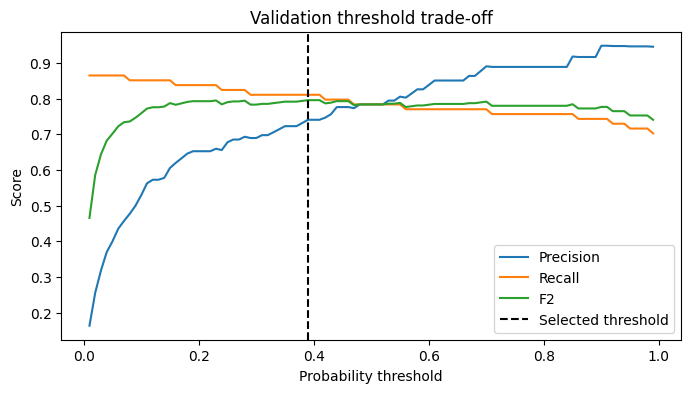

In [22]:
from sklearn.metrics import fbeta_score
valid_probabilities = xgb_model.predict_proba(X_valid)[:, 1]

threshold_rows = []

for threshold in np.arange(0.01, 1.00, 0.01):
    predictions = (valid_probabilities >= threshold).astype("int8")

    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_valid, predictions, zero_division=0),
        "recall": recall_score(y_valid, predictions, zero_division=0),
        "F1": f1_score(y_valid, predictions, zero_division=0),
        "F2": fbeta_score(
            y_valid, predictions, beta=2, zero_division=0
        ),
        "alerts": int(predictions.sum()),
    })

threshold_table = pd.DataFrame(threshold_rows)

best_index = threshold_table["F2"].idxmax()
best_row = threshold_table.loc[best_index]
selected_threshold = float(best_row["threshold"])

display(best_row.to_frame("best validation result"))
print("Selected threshold:", round(selected_threshold, 3))

plt.figure(figsize=(8, 4))
plt.plot(threshold_table["threshold"], threshold_table["precision"], label="Precision")
plt.plot(threshold_table["threshold"], threshold_table["recall"], label="Recall")
plt.plot(threshold_table["threshold"], threshold_table["F2"], label="F2")
plt.axvline(selected_threshold, color="black", linestyle="--", label="Selected threshold")
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title("Validation threshold trade-off")
plt.legend()
plt.show()

Selected threshold: 0.39
Average Precision: 0.8341
ROC-AUC:           0.9668
Precision:         0.8000
Recall:            0.8108
F1:                0.8054
F2:                0.8086
Fraud alerts:      75

Classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42648
       Fraud       0.80      0.81      0.81        74

    accuracy                           1.00     42722
   macro avg       0.90      0.91      0.90     42722
weighted avg       1.00      1.00      1.00     42722



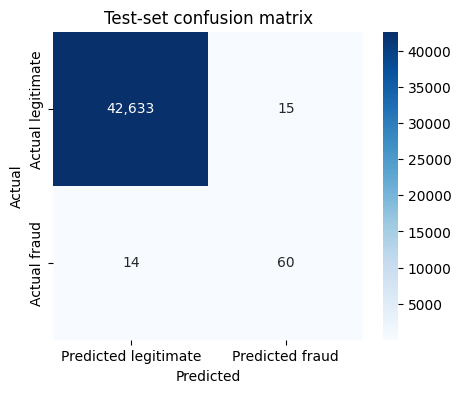

In [23]:
test_probabilities = xgb_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype("int8")

print("Selected threshold:", round(selected_threshold, 3))
print(f"Average Precision: {average_precision_score(y_test, test_probabilities):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, test_probabilities):.4f}")
print(f"Precision:         {precision_score(y_test, test_predictions, zero_division=0):.4f}")
print(f"Recall:            {recall_score(y_test, test_predictions, zero_division=0):.4f}")
print(f"F1:                {f1_score(y_test, test_predictions, zero_division=0):.4f}")
print(f"F2:                {fbeta_score(y_test, test_predictions, beta=2, zero_division=0):.4f}")
print(f"Fraud alerts:      {int(test_predictions.sum())}")

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["Predicted legitimate", "Predicted fraud"],
    yticklabels=["Actual legitimate", "Actual fraud"]
)
plt.title("Test-set confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

,importance
V14,0.474902
V10,0.081482
V4,0.069819
V12,0.036189
V8,0.023894
Amount,0.023572
V20,0.023136
V21,0.021431
V13,0.020227
V3,0.020104


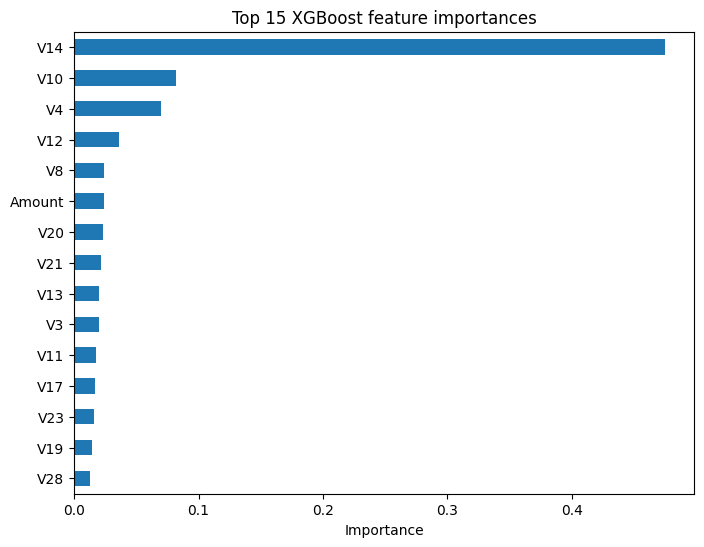

In [24]:
importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(importance.head(15).to_frame("importance"))

importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(8, 6),
    title="Top 15 XGBoost feature importances"
)
plt.xlabel("Importance")
plt.show()

In [25]:
import joblib

artifact = {
    "model": xgb_model,
    "threshold": float(selected_threshold),
    "feature_columns": list(X_train.columns),
    "random_state": RANDOM_STATE,
}

output_path = "credit_fraud_xgboost.joblib"
joblib.dump(artifact, output_path)

print("Saved:", output_path)

Saved: credit_fraud_xgboost.joblib


In [26]:
from google.colab import userdata
import base64
import os
import requests

OWNER = "DishitaRathore"
REPO = "credit-card-fraud-xgboost"
local_path = "credit_fraud_xgboost.joblib"
github_path = "models/credit_fraud_xgboost.joblib"

if not os.path.exists(local_path):
    raise FileNotFoundError(
        "The model isn't in this Colab session. "
        "Rerun the cell that saves credit_fraud_xgboost.joblib."
    )

file_size_mib = os.path.getsize(local_path) / (1024 * 1024)
print(f"Model size: {file_size_mib:.2f} MiB")

if file_size_mib >= 100:
    raise ValueError(
        "The file is at least 100 MiB. Use Git LFS for this file."
    )
elif file_size_mib > 50:
    print("GitHub warns for files over 50 MiB.")

token = userdata.get("GITHUB_TOKEN")
if not token:
    raise ValueError("Colab could not find the GITHUB_TOKEN secret.")

headers = {
    "Accept": "application/vnd.github+json",
    "Authorization": f"Bearer {token}",
    "X-GitHub-Api-Version": "2022-11-28",
}

# Confirm the repository is reachable and get its default branch.
repo_url = f"https://api.github.com/repos/{OWNER}/{REPO}"
repo_response = requests.get(repo_url, headers=headers)
repo_response.raise_for_status()
branch = repo_response.json()["default_branch"]

# Check if the file already exists; GitHub needs its SHA to replace it.
file_url = f"{repo_url}/contents/{github_path}"
existing = requests.get(
    file_url,
    headers=headers,
    params={"ref": branch}
)

if existing.status_code == 200:
    file_sha = existing.json()["sha"]
elif existing.status_code == 404:
    file_sha = None
else:
    existing.raise_for_status()

with open(local_path, "rb") as model_file:
    encoded_model = base64.b64encode(model_file.read()).decode("utf-8")

payload = {
    "message": "Add trained credit fraud model",
    "content": encoded_model,
    "branch": branch,
}

if file_sha:
    payload["sha"] = file_sha

upload_response = requests.put(file_url, headers=headers, json=payload)
upload_response.raise_for_status()

result = upload_response.json()
print("Upload successful!")
print("File:", result["content"]["html_url"])
print("Commit:", result["commit"]["html_url"])

Model size: 0.73 MiB
Upload successful!
File: https://github.com/DishitaRathore/credit-card-fraud-xgboost/blob/main/models/credit_fraud_xgboost.joblib
Commit: https://github.com/DishitaRathore/credit-card-fraud-xgboost/commit/c9da2c65e1c48eba9949894a32c89ca688569b3e
